# Exhaustive Reproduction + Ablation Study
## Latent Feature Extraction for Musical Genres from Raw Audio

This notebook is designed to answer **two separate questions**:

1. **Can we reproduce the experimental pipeline in the paper?**
2. **Which unspecified implementation assumptions explain the gap between our reproduction and the paper's reported final result?**

The notebook intentionally runs many experiments. It does **not** force numbers to match the paper.

### Paper-specified facts reproduced here

- GTZAN dataset
- four genres: `classical`, `jazz`, `pop`, `metal`
- raw waveform input
- 1-second segmentation
- 500-D input after average pooling
- 8,000 balanced examples
- 6000 / 1000 / 1000 train / dev / test split
- baseline classifier: `500 → 128 → 4`, `tanh`
- vanilla autoencoder bottleneck: 64 dimensions
- deep architecture: `500 → 256 → 192 → 128 → 64 → 128 → 192 → 256 → 500`
- final classifier branch from 64-D encoding: `64 → 32 → 16 → 4`
- combined reconstruction + classification objective
- final paper value `gamma = 0.9`
- Adam, learning rate `1e-4`, batch size `512` shown for the deep architecture
- dropout keep probability `0.9` after tuning
- PCA analysis of 64-D bottleneck and 4-D classifier logits
- precision / recall / F1 / confusion matrix

### Ambiguities we explicitly ablate

The PDF does not fully specify:

- how exactly 8,000 segments were chosen from the available audio
- how the 22.05 kHz source becomes an approximately 20,000-value one-second vector
- baseline optimizer, learning rate, batch size, epoch count
- hidden activations in the deep autoencoder/final model
- exact dropout placement
- reduction/scaling of reconstruction loss
- whether the autoencoder was pretrained before joint training
- exact training duration
- whether splitting segments from the same song across train/dev/test causes leakage

This notebook studies all of those.

---

## Runtime warning

`RUN_LEVEL = "FULL"` is intentionally extensive and can take **hours** on Colab depending on GPU/CPU.

- `"FULL"` = exhaustive study (recommended for your final run)
- `"STANDARD"` = medium-sized sweep
- `"SMOKE"` = tiny test to make sure every cell works

For your requested final experiment, leave it as **FULL**.

In [ ]:
# Cell 1 — Install dependencies
!pip install -q kagglehub librosa tensorflow scikit-learn pandas matplotlib tqdm

In [ ]:
# Cell 2 — Imports

import os
import gc
import json
import math
import time
import random
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import librosa
import kagglehub
import tensorflow as tf

from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    silhouette_score
)

warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


In [ ]:
# Cell 3 — Global experiment configuration

RUN_LEVEL = "FULL"      # "FULL", "STANDARD", or "SMOKE"
SEED = 42

# Optional persistence in Google Drive.
# Set True BEFORE running if you want results to survive Colab restarts.
USE_GOOGLE_DRIVE = False

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULT_DIR = Path("/content/drive/MyDrive/music_feature_reproduction_results")
else:
    RESULT_DIR = Path("/content/music_feature_reproduction_results")

RESULT_DIR.mkdir(parents=True, exist_ok=True)

CACHE_DIR = RESULT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = RESULT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("RUN_LEVEL:", RUN_LEVEL)
print("Results:", RESULT_DIR)

RUN_LEVEL: FULL
Results: /content/music_feature_reproduction_results


In [ ]:
# Cell 4 — Reproducibility helper

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()

## 1. Download GTZAN and define the paper's genre subset

In [ ]:
# Cell 5 — Download GTZAN

dataset_root = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)

audio_root = Path(dataset_root) / "Data" / "genres_original"

genres = ["classical", "jazz", "pop", "metal"]

label_map = {
    "classical": 0,
    "jazz": 1,
    "pop": 2,
    "metal": 3,
}

id_to_genre = {v: k for k, v in label_map.items()}

print("Dataset:", dataset_root)
print("Audio root:", audio_root)

100%|██████████| 1.21G/1.21G [00:16<00:00, 79.5MB/s]

Extracting files...


Dataset: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1
Audio root: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/genres_original


## 2. Preprocessing ambiguity study

The source audio is nominally 22.05 kHz, but the paper describes a one-second example as approximately \(R^{20000}\), followed by average pooling with pool size 40 to obtain 500 dimensions.

We therefore test three plausible interpretations:

### `resample20k`
Load/resample audio to 20 kHz → exact 20,000 samples per second → reshape `500 × 40` → mean pool.

### `native_crop20k`
Load at native sampling rate → take each true 22,050-sample second → keep the first 20,000 samples → pool by 40.

### `native_adaptive500`
Load at native sampling rate → take each true one-second segment → average it into exactly 500 approximately equal temporal bins.

These are **ablation variants**, not claims about the authors' hidden implementation.

In [ ]:
# Cell 6 — Preprocessing functions

def pool_to_500_from_20000(segment):
    segment = np.asarray(segment[:20000], dtype=np.float32)
    if len(segment) < 20000:
        segment = np.pad(segment, (0, 20000 - len(segment)))
    return segment.reshape(500, 40).mean(axis=1).astype(np.float32)


def adaptive_mean_pool_500(segment):
    segment = np.asarray(segment, dtype=np.float32)
    edges = np.linspace(0, len(segment), 501).astype(int)
    pooled = np.empty(500, dtype=np.float32)
    for i in range(500):
        chunk = segment[edges[i]:edges[i+1]]
        pooled[i] = chunk.mean() if len(chunk) else 0.0
    return pooled


def process_audio_file(file_path, preprocessing="resample20k"):
    if preprocessing == "resample20k":
        audio, _ = librosa.load(file_path, sr=20000, mono=True)
        seg_len = 20000
        n_segments = len(audio) // seg_len
        return [
            pool_to_500_from_20000(audio[i*seg_len:(i+1)*seg_len])
            for i in range(n_segments)
        ]

    elif preprocessing == "native_crop20k":
        audio, sr = librosa.load(file_path, sr=None, mono=True)
        seg_len = int(sr)
        n_segments = len(audio) // seg_len
        return [
            pool_to_500_from_20000(audio[i*seg_len:(i+1)*seg_len])
            for i in range(n_segments)
        ]

    elif preprocessing == "native_adaptive500":
        audio, sr = librosa.load(file_path, sr=None, mono=True)
        seg_len = int(sr)
        n_segments = len(audio) // seg_len
        return [
            adaptive_mean_pool_500(audio[i*seg_len:(i+1)*seg_len])
            for i in range(n_segments)
        ]

    else:
        raise ValueError(f"Unknown preprocessing mode: {preprocessing}")

In [ ]:
# Cell 7 — Build/cache all raw one-second segments for a preprocessing variant

def build_all_segments(preprocessing="resample20k", force=False):
    cache_file = CACHE_DIR / f"all_segments_{preprocessing}.npz"

    if cache_file.exists() and not force:
        d = np.load(cache_file, allow_pickle=True)
        return d["X"], d["y"], d["song_ids"], d["segment_ids"], d["bad_files"].tolist()

    X_all, y_all, song_ids, segment_ids, bad_files = [], [], [], [], []

    for genre in genres:
        folder = audio_root / genre
        print("Processing", preprocessing, ":", genre)

        for filename in sorted(os.listdir(folder)):
            if not filename.lower().endswith(".wav"):
                continue

            path = folder / filename

            try:
                segments = process_audio_file(path, preprocessing)

                for seg_idx, seg in enumerate(segments):
                    X_all.append(seg)
                    y_all.append(label_map[genre])
                    song_ids.append(filename)
                    segment_ids.append(seg_idx)

            except Exception as exc:
                print("Skipping:", filename)
                bad_files.append(f"{filename}: {exc}")

    X_all = np.asarray(X_all, dtype=np.float32)
    y_all = np.asarray(y_all, dtype=np.int32)
    song_ids = np.asarray(song_ids, dtype=object)
    segment_ids = np.asarray(segment_ids, dtype=np.int32)

    np.savez_compressed(
        cache_file,
        X=X_all,
        y=y_all,
        song_ids=song_ids,
        segment_ids=segment_ids,
        bad_files=np.asarray(bad_files, dtype=object)
    )

    return X_all, y_all, song_ids, segment_ids, bad_files

## 3. 8,000-example selection ambiguity

400 songs × 20 one-second segments = exactly 8,000 examples, which is a plausible explanation for the paper's reported total.

We therefore compare:

- `random_2000_per_genre`: random 2,000 segments per genre.
- `first20_per_song`: preferentially first 20 segments from each song, then fill any shortfall caused by unreadable/missing files.
- `even20_per_song`: 20 approximately evenly spaced segments per song, then fill any shortfall.

All strategies remain balanced at 2,000 examples per genre.

In [ ]:
# Cell 8 — 8,000-example selection strategies

def select_8000(X_all, y_all, song_ids, segment_ids, strategy="random_2000_per_genre", seed=SEED):
    rng = np.random.default_rng(seed)
    selected = []

    for label in range(4):
        label_idx = np.where(y_all == label)[0]

        if strategy == "random_2000_per_genre":
            chosen = rng.choice(label_idx, size=2000, replace=False)

        else:
            chosen_list = []
            label_songs = sorted(np.unique(song_ids[label_idx]))

            for song in label_songs:
                idx = label_idx[song_ids[label_idx] == song]
                idx = idx[np.argsort(segment_ids[idx])]

                if strategy == "first20_per_song":
                    take = idx[:20]

                elif strategy == "even20_per_song":
                    if len(idx) <= 20:
                        take = idx
                    else:
                        positions = np.linspace(0, len(idx)-1, 20).round().astype(int)
                        take = idx[positions]

                else:
                    raise ValueError(strategy)

                chosen_list.extend(take.tolist())

            chosen_list = list(dict.fromkeys(chosen_list))

            if len(chosen_list) < 2000:
                remaining = np.setdiff1d(label_idx, np.asarray(chosen_list, dtype=int))
                extra = rng.choice(remaining, size=2000-len(chosen_list), replace=False)
                chosen_list.extend(extra.tolist())

            if len(chosen_list) > 2000:
                chosen_list = rng.choice(np.asarray(chosen_list), size=2000, replace=False).tolist()

            chosen = np.asarray(chosen_list, dtype=int)

        selected.extend(chosen.tolist())

    selected = np.asarray(selected, dtype=int)
    rng.shuffle(selected)

    return (
        X_all[selected],
        y_all[selected],
        song_ids[selected],
        segment_ids[selected],
    )

In [ ]:
# Cell 9 — Paper-style segment-random 6000/1000/1000 split

def segment_random_split(X, y, song_ids, segment_ids, seed=SEED):
    idx = np.arange(len(X))

    tr_idx, tmp_idx = train_test_split(
        idx,
        train_size=6000,
        test_size=2000,
        stratify=y,
        random_state=seed
    )

    va_idx, te_idx = train_test_split(
        tmp_idx,
        train_size=1000,
        test_size=1000,
        stratify=y[tmp_idx],
        random_state=seed
    )

    def pack(ii):
        return X[ii], y[ii], song_ids[ii], segment_ids[ii]

    return pack(tr_idx), pack(va_idx), pack(te_idx)

In [ ]:
# Cell 10 — Song-disjoint split for leakage robustness analysis

def song_disjoint_split(X, y, song_ids, segment_ids, seed=SEED):
    rng = np.random.default_rng(seed)

    train_idx, val_idx, test_idx = [], [], []

    # exact target examples per class: 1500 / 250 / 250
    for label in range(4):
        label_indices = np.where(y == label)[0]
        songs = np.unique(song_ids[label_indices]).copy()
        rng.shuffle(songs)

        n = len(songs)
        n_train_songs = max(1, int(round(n * 0.75)))
        n_val_songs = max(1, int(round(n * 0.125)))

        train_songs = songs[:n_train_songs]
        val_songs = songs[n_train_songs:n_train_songs+n_val_songs]
        test_songs = songs[n_train_songs+n_val_songs:]

        if len(test_songs) == 0:
            test_songs = val_songs[-1:]
            val_songs = val_songs[:-1]

        def indices_for(song_set):
            return label_indices[np.isin(song_ids[label_indices], song_set)]

        tr_pool = indices_for(train_songs)
        va_pool = indices_for(val_songs)
        te_pool = indices_for(test_songs)

        # If the selected 8000 dataset does not contain enough examples in one song group,
        # fail clearly rather than silently violating song disjointness.
        if len(tr_pool) < 1500 or len(va_pool) < 250 or len(te_pool) < 250:
            raise RuntimeError(
                f"Not enough examples for label {label}: "
                f"train={len(tr_pool)}, val={len(va_pool)}, test={len(te_pool)}. "
                "Use a selection strategy with better per-song coverage (first20/even20)."
            )

        train_idx.extend(rng.choice(tr_pool, 1500, replace=False))
        val_idx.extend(rng.choice(va_pool, 250, replace=False))
        test_idx.extend(rng.choice(te_pool, 250, replace=False))

    train_idx = np.asarray(train_idx)
    val_idx = np.asarray(val_idx)
    test_idx = np.asarray(test_idx)

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    rng.shuffle(test_idx)

    def pack(ii):
        return X[ii], y[ii], song_ids[ii], segment_ids[ii]

    return pack(train_idx), pack(val_idx), pack(test_idx)

## 4. Common model builders and experiment utilities

In [ ]:
# Cell 11 — Loss functions

def reconstruction_loss_sum(y_true, y_pred):
    # Mean over batch of per-example squared L2 sum.
    return tf.reduce_mean(
        tf.reduce_sum(tf.square(y_true - y_pred), axis=1)
    )

def reconstruction_loss_mean(y_true, y_pred):
    # Standard element-wise MSE.
    return tf.reduce_mean(tf.square(y_true - y_pred))

def get_reconstruction_loss(mode):
    if mode == "sum":
        return reconstruction_loss_sum
    elif mode == "mean":
        return reconstruction_loss_mean
    else:
        raise ValueError(mode)

In [ ]:
# Cell 12 — Model builders

def act_value(name):
    if name == "linear":
        return None
    return name


def build_baseline(lr=1e-3, activation="tanh", seed=SEED):
    tf.keras.backend.clear_session()
    set_seed(seed)

    inp = tf.keras.layers.Input(shape=(500,))
    x = tf.keras.layers.Dense(128, activation=act_value(activation), name="baseline_hidden")(inp)
    logits = tf.keras.layers.Dense(4, name="baseline_logits")(x)

    model = tf.keras.Model(inp, logits)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"]
    )
    return model


def build_autoencoder(
    lr=1e-4,
    activation="tanh",
    latent_activation="tanh",
    dropout=0.0,
    loss_mode="mean",
    seed=SEED
):
    tf.keras.backend.clear_session()
    set_seed(seed)

    inp = tf.keras.layers.Input(shape=(500,), name="ae_input")

    x = tf.keras.layers.Dense(256, activation=act_value(activation), name="enc_256")(inp)
    if dropout > 0: x = tf.keras.layers.Dropout(dropout)(x)

    x = tf.keras.layers.Dense(192, activation=act_value(activation), name="enc_192")(x)
    if dropout > 0: x = tf.keras.layers.Dropout(dropout)(x)

    x = tf.keras.layers.Dense(128, activation=act_value(activation), name="enc_128")(x)
    if dropout > 0: x = tf.keras.layers.Dropout(dropout)(x)

    latent = tf.keras.layers.Dense(
        64,
        activation=act_value(latent_activation),
        name="latent_encoding"
    )(x)

    d = tf.keras.layers.Dense(128, activation=act_value(activation), name="dec_128")(latent)
    d = tf.keras.layers.Dense(192, activation=act_value(activation), name="dec_192")(d)
    d = tf.keras.layers.Dense(256, activation=act_value(activation), name="dec_256")(d)
    out = tf.keras.layers.Dense(500, activation=None, name="reconstruction")(d)

    ae = tf.keras.Model(inp, out, name="vanilla_autoencoder")
    encoder = tf.keras.Model(inp, latent, name="encoder")

    ae.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=get_reconstruction_loss(loss_mode)
    )

    return ae, encoder


def build_deep_softmax(
    lr=1e-4,
    activation="tanh",
    latent_activation="tanh",
    dropout=0.1,
    gamma=0.9,
    reconstruction_mode="mean",
    classifier_head=(32, 16),
    seed=SEED
):
    tf.keras.backend.clear_session()
    set_seed(seed)

    inp = tf.keras.layers.Input(shape=(500,), name="audio_input")

    e = tf.keras.layers.Dense(256, activation=act_value(activation), name="enc_256")(inp)
    if dropout > 0: e = tf.keras.layers.Dropout(dropout, name="enc_drop_256")(e)

    e = tf.keras.layers.Dense(192, activation=act_value(activation), name="enc_192")(e)
    if dropout > 0: e = tf.keras.layers.Dropout(dropout, name="enc_drop_192")(e)

    e = tf.keras.layers.Dense(128, activation=act_value(activation), name="enc_128")(e)
    if dropout > 0: e = tf.keras.layers.Dropout(dropout, name="enc_drop_128")(e)

    latent = tf.keras.layers.Dense(
        64,
        activation=act_value(latent_activation),
        name="latent_encoding"
    )(e)

    d = tf.keras.layers.Dense(128, activation=act_value(activation), name="dec_128")(latent)
    d = tf.keras.layers.Dense(192, activation=act_value(activation), name="dec_192")(d)
    d = tf.keras.layers.Dense(256, activation=act_value(activation), name="dec_256")(d)
    reconstruction = tf.keras.layers.Dense(500, activation=None, name="reconstruction")(d)

    c = latent
    for i, units in enumerate(classifier_head):
        c = tf.keras.layers.Dense(
            units,
            activation=act_value(activation),
            name=f"clf_{units}_{i}"
        )(c)
        if dropout > 0:
            c = tf.keras.layers.Dropout(dropout, name=f"clf_drop_{i}")(c)

    logits = tf.keras.layers.Dense(4, activation=None, name="genre_prediction")(c)

    model = tf.keras.Model(inp, [reconstruction, logits], name="deep_softmax_autoencoder")
    encoder = tf.keras.Model(inp, latent, name="deep_encoder")
    logit_model = tf.keras.Model(inp, logits, name="deep_logits")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss={
            "reconstruction": get_reconstruction_loss(reconstruction_mode),
            "genre_prediction": tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        },
        loss_weights={
            "reconstruction": gamma,
            "genre_prediction": 1.0 - gamma,
        },
        metrics={
            "genre_prediction": ["accuracy"]
        }
    )

    return model, encoder, logit_model

In [ ]:
# Cell 13 — Weight transfer helpers for pretraining experiments

ENCODER_LAYER_NAMES = ["enc_256", "enc_192", "enc_128", "latent_encoding"]
DECODER_LAYER_NAMES = ["dec_128", "dec_192", "dec_256", "reconstruction"]

def copy_named_weights(source_model, target_model, names):
    copied = []
    for name in names:
        try:
            src = source_model.get_layer(name)
            dst = target_model.get_layer(name)
            dst.set_weights(src.get_weights())
            copied.append(name)
        except Exception:
            pass
    return copied


def set_named_trainable(model, names, trainable):
    for name in names:
        try:
            model.get_layer(name).trainable = trainable
        except Exception:
            pass

In [ ]:
# Cell 14 — Experiment logging

def append_result(csv_name, row):
    path = RESULT_DIR / csv_name

    new = pd.DataFrame([row])

    if path.exists():
        old = pd.read_csv(path)
        out = pd.concat([old, new], ignore_index=True)
    else:
        out = new

    out.to_csv(path, index=False)
    return out


def clean_memory():
    tf.keras.backend.clear_session()
    gc.collect()

In [ ]:
# Cell 15 — Training/evaluation functions

def run_baseline_experiment(
    split,
    lr,
    epochs,
    batch_size,
    activation="tanh",
    seed=SEED,
    verbose=0
):
    (Xtr, ytr, _, _), (Xva, yva, _, _), _ = split

    model = build_baseline(lr=lr, activation=activation, seed=seed)

    start = time.time()
    history = model.fit(
        Xtr, ytr,
        validation_data=(Xva, yva),
        epochs=epochs,
        batch_size=batch_size,
        verbose=verbose
    )

    tr = model.evaluate(Xtr, ytr, verbose=0, return_dict=True)
    va = model.evaluate(Xva, yva, verbose=0, return_dict=True)

    row = {
        "lr": lr,
        "epochs": epochs,
        "batch_size": batch_size,
        "activation": activation,
        "seed": seed,
        "train_acc": tr["accuracy"],
        "val_acc": va["accuracy"],
        "best_val_acc_during_training": float(np.max(history.history["val_accuracy"])),
        "best_epoch": int(np.argmax(history.history["val_accuracy"]) + 1),
        "seconds": time.time() - start,
    }

    clean_memory()
    return row


def latent_probe_metrics(encoder, Xtr, ytr, Xva, yva):
    Ztr = encoder.predict(Xtr, batch_size=512, verbose=0)
    Zva = encoder.predict(Xva, batch_size=512, verbose=0)

    probe = LogisticRegression(max_iter=1500, random_state=SEED)
    probe.fit(Ztr, ytr)
    acc = probe.score(Zva, yva)

    sil = np.nan
    try:
        sil = silhouette_score(Zva, yva)
    except Exception:
        pass

    return float(acc), float(sil)


def run_ae_experiment(
    split,
    lr,
    epochs,
    batch_size,
    activation,
    latent_activation,
    dropout,
    loss_mode,
    seed=SEED,
    verbose=0
):
    (Xtr, ytr, _, _), (Xva, yva, _, _), _ = split

    ae, encoder = build_autoencoder(
        lr=lr,
        activation=activation,
        latent_activation=latent_activation,
        dropout=dropout,
        loss_mode=loss_mode,
        seed=seed
    )

    start = time.time()

    hist = ae.fit(
        Xtr, Xtr,
        validation_data=(Xva, Xva),
        epochs=epochs,
        batch_size=batch_size,
        verbose=verbose
    )

    train_recon = float(ae.evaluate(Xtr, Xtr, verbose=0))
    val_recon = float(ae.evaluate(Xva, Xva, verbose=0))

    probe_acc, sil = latent_probe_metrics(encoder, Xtr, ytr, Xva, yva)

    row = {
        "lr": lr,
        "epochs": epochs,
        "batch_size": batch_size,
        "activation": activation,
        "latent_activation": latent_activation,
        "dropout": dropout,
        "loss_mode": loss_mode,
        "seed": seed,
        "train_recon": train_recon,
        "val_recon": val_recon,
        "probe_val_acc": probe_acc,
        "val_silhouette": sil,
        "best_val_recon": float(np.min(hist.history["val_loss"])),
        "best_epoch": int(np.argmin(hist.history["val_loss"]) + 1),
        "seconds": time.time() - start,
    }

    clean_memory()
    return row

In [ ]:
# Cell 16 — Deep Softmax experiment runner

def run_deep_experiment(
    split,
    lr,
    epochs,
    batch_size,
    activation,
    latent_activation,
    dropout,
    gamma,
    reconstruction_mode,
    classifier_head=(32,16),
    seed=SEED,
    pretrain_mode="none",
    pretrained_ae=None,
    freeze_warmup_epochs=30,
    verbose=0
):
    (Xtr, ytr, _, _), (Xva, yva, _, _), _ = split

    model, encoder, logit_model = build_deep_softmax(
        lr=lr,
        activation=activation,
        latent_activation=latent_activation,
        dropout=dropout,
        gamma=gamma,
        reconstruction_mode=reconstruction_mode,
        classifier_head=classifier_head,
        seed=seed
    )

    copied = []

    if pretrain_mode != "none":
        if pretrained_ae is None:
            raise ValueError("pretrained_ae required")

        copied += copy_named_weights(
            pretrained_ae,
            model,
            ENCODER_LAYER_NAMES
        )

        if pretrain_mode in ["encoder_decoder", "freeze_then_finetune"]:
            copied += copy_named_weights(
                pretrained_ae,
                model,
                DECODER_LAYER_NAMES
            )

    start = time.time()

    if pretrain_mode == "freeze_then_finetune":
        # Freeze encoder temporarily.
        set_named_trainable(model, ENCODER_LAYER_NAMES, False)

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss={
                "reconstruction": get_reconstruction_loss(reconstruction_mode),
                "genre_prediction": tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            },
            loss_weights={
                "reconstruction": gamma,
                "genre_prediction": 1.0-gamma,
            },
            metrics={"genre_prediction": ["accuracy"]}
        )

        warm_epochs = min(freeze_warmup_epochs, max(1, epochs // 3))

        model.fit(
            Xtr,
            {"reconstruction": Xtr, "genre_prediction": ytr},
            validation_data=(
                Xva,
                {"reconstruction": Xva, "genre_prediction": yva}
            ),
            epochs=warm_epochs,
            batch_size=batch_size,
            verbose=verbose
        )

        set_named_trainable(model, ENCODER_LAYER_NAMES, True)

        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
            loss={
                "reconstruction": get_reconstruction_loss(reconstruction_mode),
                "genre_prediction": tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            },
            loss_weights={
                "reconstruction": gamma,
                "genre_prediction": 1.0-gamma,
            },
            metrics={"genre_prediction": ["accuracy"]}
        )

        hist = model.fit(
            Xtr,
            {"reconstruction": Xtr, "genre_prediction": ytr},
            validation_data=(
                Xva,
                {"reconstruction": Xva, "genre_prediction": yva}
            ),
            epochs=max(1, epochs-warm_epochs),
            batch_size=batch_size,
            verbose=verbose
        )

    else:
        hist = model.fit(
            Xtr,
            {"reconstruction": Xtr, "genre_prediction": ytr},
            validation_data=(
                Xva,
                {"reconstruction": Xva, "genre_prediction": yva}
            ),
            epochs=epochs,
            batch_size=batch_size,
            verbose=verbose
        )

    train_results = model.evaluate(
        Xtr,
        {"reconstruction": Xtr, "genre_prediction": ytr},
        verbose=0,
        return_dict=True
    )

    val_results = model.evaluate(
        Xva,
        {"reconstruction": Xva, "genre_prediction": yva},
        verbose=0,
        return_dict=True
    )

    val_logits = logit_model.predict(Xva, batch_size=512, verbose=0)
    val_pred = np.argmax(val_logits, axis=1)
    macro_f1 = precision_recall_fscore_support(
        yva, val_pred, average="macro", zero_division=0
    )[2]

    # Diagnostic: numerical scale of each raw component on validation set
    val_recon_pred, _ = model.predict(Xva[:min(512, len(Xva))], verbose=0)
    if reconstruction_mode == "sum":
        recon_component = np.mean(np.sum((Xva[:len(val_recon_pred)] - val_recon_pred)**2, axis=1))
    else:
        recon_component = np.mean((Xva[:len(val_recon_pred)] - val_recon_pred)**2)

    # approximate CE
    ce_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    ce_component = float(ce_fn(yva, val_logits).numpy())

    row = {
        "lr": lr,
        "epochs": epochs,
        "batch_size": batch_size,
        "activation": activation,
        "latent_activation": latent_activation,
        "dropout": dropout,
        "gamma": gamma,
        "reconstruction_mode": reconstruction_mode,
        "classifier_head": str(tuple(classifier_head)),
        "seed": seed,
        "pretrain_mode": pretrain_mode,
        "copied_layers": ",".join(copied),
        "train_acc": float(train_results["genre_prediction_accuracy"]),
        "val_acc": float(val_results["genre_prediction_accuracy"]),
        "val_macro_f1": float(macro_f1),
        "raw_val_recon_component": float(recon_component),
        "raw_val_ce_component": float(ce_component),
        "weighted_recon_component": float(gamma * recon_component),
        "weighted_ce_component": float((1-gamma) * ce_component),
        "loss_component_ratio_recon_to_ce": float(
            (gamma * recon_component) / max((1-gamma) * ce_component, 1e-12)
        ),
        "seconds": time.time() - start,
    }

    # Handle either history from normal run or post-warmup.
    acc_key = "val_genre_prediction_accuracy"
    if acc_key in hist.history:
        row["best_val_acc_during_training"] = float(np.max(hist.history[acc_key]))
        row["best_epoch_in_recorded_stage"] = int(np.argmax(hist.history[acc_key]) + 1)
    else:
        row["best_val_acc_during_training"] = row["val_acc"]
        row["best_epoch_in_recorded_stage"] = epochs

    clean_memory()
    return row

## 5. Build the default paper-like dataset

In [ ]:
# Cell 17 — Default dataset used for the main paper reproduction and most ablations

X_all, y_all, song_all, seg_all, bad_files = build_all_segments("resample20k")

X, y, song_ids, segment_ids = select_8000(
    X_all, y_all, song_all, seg_all,
    strategy="random_2000_per_genre",
    seed=SEED
)

paper_split = segment_random_split(
    X, y, song_ids, segment_ids, seed=SEED
)

print("Bad files:", bad_files[:5])

for name, part in zip(["Train", "Validation", "Test"], paper_split):
    Xp, yp, sp, sgp = part
    print(name, Xp.shape, np.unique(yp, return_counts=True)[1])

Processing resample20k : classical
Processing resample20k : jazz
Skipping: jazz.00054.wav
Processing resample20k : pop
Processing resample20k : metal
Bad files: ['jazz.00054.wav: ']
Train (6000, 500) [1500 1500 1500 1500]
Validation (1000, 500) [250 250 250 250]
Test (1000, 500) [250 250 250 250]


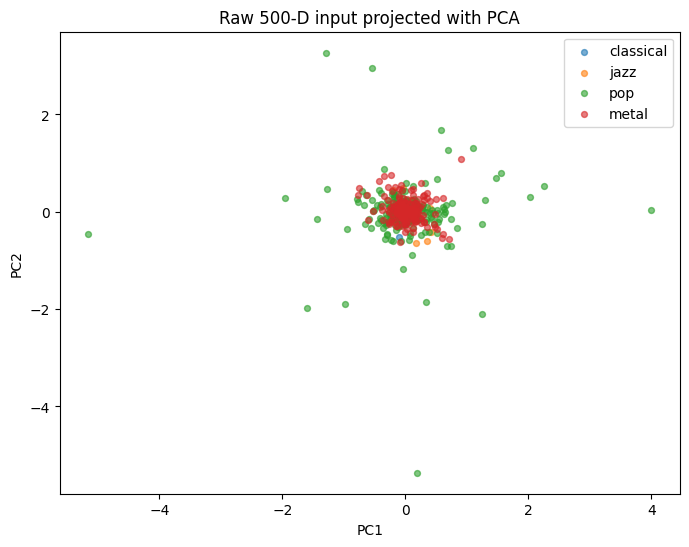

In [ ]:
# Cell 18 — Raw-input PCA (paper Figure 1 style)

(_, _, _, _), (_, _, _, _), (X_test, y_test, _, _) = paper_split

pca = PCA(n_components=2)
raw_2d = pca.fit_transform(X_test)

plt.figure(figsize=(8,6))
for label, genre in enumerate(genres):
    idx = y_test == label
    plt.scatter(raw_2d[idx,0], raw_2d[idx,1], s=18, alpha=0.6, label=genre)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Raw 500-D input projected with PCA")
plt.legend()
plt.show()

# ABLATION STUDY A — Data preprocessing and 8,000-example selection

This stage asks whether our biggest uncertainty is **before the neural network even starts**.

We train the same baseline configuration on combinations of:

- preprocessing interpretation
- 8,000-example selection rule

We use validation accuracy only for selection.

In [ ]:
# Cell 19 — Data ablation search space

if RUN_LEVEL == "SMOKE":
    PREPROCESSING_MODES = ["resample20k"]
    SELECTION_MODES = ["random_2000_per_genre", "first20_per_song"]
elif RUN_LEVEL == "STANDARD":
    PREPROCESSING_MODES = ["resample20k", "native_crop20k"]
    SELECTION_MODES = ["random_2000_per_genre", "first20_per_song", "even20_per_song"]
else:
    PREPROCESSING_MODES = ["resample20k", "native_crop20k", "native_adaptive500"]
    SELECTION_MODES = ["random_2000_per_genre", "first20_per_song", "even20_per_song"]

data_ablation_rows = []

In [ ]:
# Cell 20 — Run preprocessing/selection ablation

for prep in PREPROCESSING_MODES:
    Xa, ya, sa, ga, bad = build_all_segments(prep)

    for selection in SELECTION_MODES:
        X8, y8, s8, g8 = select_8000(
            Xa, ya, sa, ga,
            strategy=selection,
            seed=SEED
        )

        split = segment_random_split(X8, y8, s8, g8, seed=SEED)

        row = run_baseline_experiment(
            split=split,
            lr=1e-3,
            epochs=50,
            batch_size=32,
            activation="tanh",
            seed=SEED,
            verbose=0
        )

        row.update({
            "preprocessing": prep,
            "selection": selection
        })

        data_ablation_rows.append(row)

        print(
            prep,
            selection,
            "val=", round(row["val_acc"], 4)
        )

data_ablation_df = pd.DataFrame(data_ablation_rows)
data_ablation_df.to_csv(RESULT_DIR / "01_data_ablation.csv", index=False)

data_ablation_df.sort_values("val_acc", ascending=False)

resample20k random_2000_per_genre val= 0.505
resample20k first20_per_song val= 0.521
resample20k even20_per_song val= 0.519
Processing native_crop20k : classical
Processing native_crop20k : jazz
Skipping: jazz.00054.wav
Processing native_crop20k : pop
Processing native_crop20k : metal
native_crop20k random_2000_per_genre val= 0.493
native_crop20k first20_per_song val= 0.522
native_crop20k even20_per_song val= 0.521
Processing native_adaptive500 : classical
Processing native_adaptive500 : jazz
Skipping: jazz.00054.wav
Processing native_adaptive500 : pop
Processing native_adaptive500 : metal
native_adaptive500 random_2000_per_genre val= 0.503
native_adaptive500 first20_per_song val= 0.52
native_adaptive500 even20_per_song val= 0.52


,lr,epochs,batch_size,activation,seed,train_acc,val_acc,best_val_acc_during_training,best_epoch,seconds,preprocessing,selection
4,0.001,50,32,tanh,42,0.754833,0.522,0.524,49,40.081578,native_crop20k,first20_per_song
5,0.001,50,32,tanh,42,0.754167,0.521,0.521,50,38.081408,native_crop20k,even20_per_song
1,0.001,50,32,tanh,42,0.744667,0.521,0.521,50,39.846388,resample20k,first20_per_song
8,0.001,50,32,tanh,42,0.748500,0.520,0.520,50,38.645905,native_adaptive500,even20_per_song
7,0.001,50,32,tanh,42,0.743667,0.520,0.520,50,38.662867,native_adaptive500,first20_per_song
2,0.001,50,32,tanh,42,0.749167,0.519,0.519,50,38.749227,resample20k,even20_per_song
0,0.001,50,32,tanh,42,0.754167,0.505,0.505,50,39.463329,resample20k,random_2000_per_genre
6,0.001,50,32,tanh,42,0.754500,0.503,0.505,49,39.803026,native_adaptive500,random_2000_per_genre
3,0.001,50,32,tanh,42,0.757000,0.493,0.493,50,38.840293,native_crop20k,random_2000_per_genre


For the rest of the **main reproduction**, we keep the paper-like default dataset (`resample20k + random_2000_per_genre`) so later results are comparable.

The data ablation above is diagnostic; it does not silently replace the main dataset.

# ABLATION STUDY B — Baseline classifier

The architecture is fixed by the paper: `500 → 128(tanh) → 4`.

We therefore ablate only unspecified training choices:
- learning rate
- epochs
- batch size
- random seed

The test set is **not used** to select these.

In [ ]:
# Cell 21 — Baseline LR × epoch grid

if RUN_LEVEL == "SMOKE":
    BASE_LRS = [1e-3]
    BASE_EPOCHS = [10, 25]
elif RUN_LEVEL == "STANDARD":
    BASE_LRS = [1e-4, 1e-3, 3e-3]
    BASE_EPOCHS = [25, 50, 100]
else:
    BASE_LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
    BASE_EPOCHS = [10, 25, 50, 100, 200]

baseline_grid_rows = []

for lr in BASE_LRS:
    for epochs in BASE_EPOCHS:
        row = run_baseline_experiment(
            paper_split,
            lr=lr,
            epochs=epochs,
            batch_size=32,
            activation="tanh",
            seed=SEED
        )
        baseline_grid_rows.append(row)
        print(lr, epochs, "val=", round(row["val_acc"], 4))

baseline_grid_df = pd.DataFrame(baseline_grid_rows)
baseline_grid_df.to_csv(RESULT_DIR / "02_baseline_lr_epoch.csv", index=False)

baseline_grid_df.sort_values("val_acc", ascending=False).head(20)

0.0001 10 val= 0.379
0.0001 25 val= 0.398
0.0001 50 val= 0.403
0.0001 100 val= 0.388
0.0001 200 val= 0.393
0.0003 10 val= 0.391
0.0003 25 val= 0.395
0.0003 50 val= 0.387
0.0003 100 val= 0.416
0.0003 200 val= 0.495
0.001 10 val= 0.392
0.001 25 val= 0.404
0.001 50 val= 0.505
0.001 100 val= 0.54
0.001 200 val= 0.509
0.003 10 val= 0.433
0.003 25 val= 0.533
0.003 50 val= 0.53
0.003 100 val= 0.494
0.003 200 val= 0.441
0.01 10 val= 0.49
0.01 25 val= 0.538
0.01 50 val= 0.527
0.01 100 val= 0.524
0.01 200 val= 0.482


,lr,epochs,batch_size,activation,seed,train_acc,val_acc,best_val_acc_during_training,best_epoch,seconds
13,0.0010,100,32,tanh,42,0.910167,0.540,0.543,74,77.725271
21,0.0100,25,32,tanh,42,0.975667,0.538,0.548,23,21.153317
16,0.0030,25,32,tanh,42,0.824333,0.533,0.538,23,20.626011
17,0.0030,50,32,tanh,42,0.946833,0.530,0.549,39,39.816231
22,0.0100,50,32,tanh,42,0.992167,0.527,0.548,23,38.483742
23,0.0100,100,32,tanh,42,0.998333,0.524,0.548,23,80.049617
14,0.0010,200,32,tanh,42,0.989167,0.509,0.548,127,146.058383
12,0.0010,50,32,tanh,42,0.754167,0.505,0.505,50,38.551974
9,0.0003,200,32,tanh,42,0.791000,0.495,0.497,191,150.261336
18,0.0030,100,32,tanh,42,0.995500,0.494,0.549,39,78.501422


In [ ]:
# Cell 22 — Baseline batch-size sweep using best LR/epoch pair

best_base = baseline_grid_df.sort_values(
    ["val_acc", "best_val_acc_during_training"],
    ascending=False
).iloc[0]

if RUN_LEVEL == "SMOKE":
    BASE_BATCHES = [32, 512]
elif RUN_LEVEL == "STANDARD":
    BASE_BATCHES = [32, 128, 512]
else:
    BASE_BATCHES = [16, 32, 64, 128, 256, 512, 1024]

baseline_batch_rows = []

for bs in BASE_BATCHES:
    row = run_baseline_experiment(
        paper_split,
        lr=float(best_base.lr),
        epochs=int(best_base.epochs),
        batch_size=bs,
        activation="tanh",
        seed=SEED
    )
    baseline_batch_rows.append(row)
    print("batch", bs, "val=", round(row["val_acc"], 4))

baseline_batch_df = pd.DataFrame(baseline_batch_rows)
baseline_batch_df.to_csv(RESULT_DIR / "03_baseline_batch.csv", index=False)

baseline_batch_df.sort_values("val_acc", ascending=False)

batch 16 val= 0.547
batch 32 val= 0.54
batch 64 val= 0.527
batch 128 val= 0.499
batch 256 val= 0.461
batch 512 val= 0.431
batch 1024 val= 0.406


,lr,epochs,batch_size,activation,seed,train_acc,val_acc,best_val_acc_during_training,best_epoch,seconds
0,0.001,100,16,tanh,42,0.960833,0.547,0.556,75,120.119992
1,0.001,100,32,tanh,42,0.910167,0.540,0.543,74,75.747316
2,0.001,100,64,tanh,42,0.839000,0.527,0.527,100,45.864578
3,0.001,100,128,tanh,42,0.771333,0.499,0.499,100,31.034734
4,0.001,100,256,tanh,42,0.697167,0.461,0.461,95,24.397392
5,0.001,100,512,tanh,42,0.628000,0.431,0.431,100,20.221588
6,0.001,100,1024,tanh,42,0.583833,0.406,0.407,98,17.117572


In [ ]:
# Cell 23 — Baseline seed robustness

best_base_batch = baseline_batch_df.sort_values("val_acc", ascending=False).iloc[0]

BASE_SEEDS = [42] if RUN_LEVEL == "SMOKE" else ([1, 42, 123] if RUN_LEVEL == "STANDARD" else [1, 7, 21, 42, 123, 777, 2026])

baseline_seed_rows = []

for seed in BASE_SEEDS:
    row = run_baseline_experiment(
        paper_split,
        lr=float(best_base_batch.lr),
        epochs=int(best_base_batch.epochs),
        batch_size=int(best_base_batch.batch_size),
        activation="tanh",
        seed=seed
    )
    baseline_seed_rows.append(row)

baseline_seed_df = pd.DataFrame(baseline_seed_rows)
baseline_seed_df.to_csv(RESULT_DIR / "04_baseline_seeds.csv", index=False)

display(baseline_seed_df)
print("Mean val accuracy:", baseline_seed_df.val_acc.mean())
print("Std val accuracy :", baseline_seed_df.val_acc.std())

# ABLATION STUDY C — Vanilla autoencoder

The autoencoder is unsupervised, so we record:

- train reconstruction loss
- validation reconstruction loss
- a **linear logistic-regression probe** on the learned 64-D embedding
- silhouette score using labels only as an evaluation diagnostic

The probe does not alter the autoencoder weights.

We ablate:
- hidden activation
- latent activation
- reconstruction loss scaling (`sum` vs `mean`)
- learning rate
- epochs
- dropout

In [ ]:
# Cell 24 — Autoencoder activation × loss scaling × learning-rate screening

if RUN_LEVEL == "SMOKE":
    AE_ACTIVATIONS = ["tanh"]
    AE_LATENT_ACTS = ["tanh"]
    AE_LOSS_MODES = ["sum", "mean"]
    AE_LRS = [1e-4]
    AE_SCREEN_EPOCHS = 30
elif RUN_LEVEL == "STANDARD":
    AE_ACTIVATIONS = ["tanh", "relu"]
    AE_LATENT_ACTS = ["tanh"]
    AE_LOSS_MODES = ["sum", "mean"]
    AE_LRS = [1e-4, 1e-3]
    AE_SCREEN_EPOCHS = 100
else:
    AE_ACTIVATIONS = ["linear", "tanh", "relu", "elu"]
    AE_LATENT_ACTS = ["linear", "tanh", "relu"]
    AE_LOSS_MODES = ["sum", "mean"]
    AE_LRS = [1e-4, 3e-4, 1e-3]
    AE_SCREEN_EPOCHS = 150

ae_screen_rows = []

for activation in AE_ACTIVATIONS:
    for latent_activation in AE_LATENT_ACTS:
        for loss_mode in AE_LOSS_MODES:
            for lr in AE_LRS:
                row = run_ae_experiment(
                    paper_split,
                    lr=lr,
                    epochs=AE_SCREEN_EPOCHS,
                    batch_size=512,
                    activation=activation,
                    latent_activation=latent_activation,
                    dropout=0.0,
                    loss_mode=loss_mode,
                    seed=SEED
                )
                ae_screen_rows.append(row)
                print(
                    activation, latent_activation, loss_mode, lr,
                    "probe=", round(row["probe_val_acc"], 4),
                    "recon=", round(row["val_recon"], 6)
                )

ae_screen_df = pd.DataFrame(ae_screen_rows)
ae_screen_df.to_csv(RESULT_DIR / "05_ae_screen.csv", index=False)

ae_screen_df.sort_values(
    ["probe_val_acc", "val_recon"],
    ascending=[False, True]
).head(30)

linear linear sum 0.0001 probe= 0.372 recon= 3.467221
linear linear sum 0.0003 probe= 0.375 recon= 3.423742
linear linear sum 0.001 probe= 0.385 recon= 3.426018
linear linear mean 0.0001 probe= 0.369 recon= 0.00695
linear linear mean 0.0003 probe= 0.374 recon= 0.006848
linear linear mean 0.001 probe= 0.391 recon= 0.006846
linear tanh sum 0.0001 probe= 0.373 recon= 3.480367
linear tanh sum 0.0003 probe= 0.376 recon= 3.43082
linear tanh sum 0.001 probe= 0.391 recon= 3.427612
linear tanh mean 0.0001 probe= 0.372 recon= 0.006978
linear tanh mean 0.0003 probe= 0.38 recon= 0.006862
linear tanh mean 0.001 probe= 0.388 recon= 0.006853
linear relu sum 0.0001 probe= 0.383 recon= 3.497411
linear relu sum 0.0003 probe= 0.383 recon= 3.437827
linear relu sum 0.001 probe= 0.386 recon= 3.444905
linear relu mean 0.0001 probe= 0.383 recon= 0.007015
linear relu mean 0.0003 probe= 0.386 recon= 0.006877
linear relu mean 0.001 probe= 0.395 recon= 0.006884
tanh linear sum 0.0001 probe= 0.362 recon= 3.493349


,lr,epochs,batch_size,activation,latent_activation,dropout,loss_mode,seed,train_recon,val_recon,probe_val_acc,val_silhouette,best_val_recon,best_epoch,seconds
43,0.0003,150,512,relu,tanh,0.0,sum,42,3.280360,4.483102,0.603,-0.076452,4.429816,85,88.805966
41,0.0010,150,512,relu,linear,0.0,mean,42,0.005967,0.009891,0.596,-0.097100,0.009224,30,89.486034
38,0.0010,150,512,relu,linear,0.0,sum,42,2.882417,4.954962,0.594,-0.096428,4.614423,24,89.108046
42,0.0001,150,512,relu,tanh,0.0,sum,42,3.753242,4.361194,0.593,-0.055579,4.361193,150,92.361623
50,0.0010,150,512,relu,relu,0.0,sum,42,3.209035,5.084188,0.593,-0.033808,4.756222,26,91.344871
51,0.0001,150,512,relu,relu,0.0,mean,42,0.007945,0.008806,0.592,-0.009159,0.008806,150,87.760147
40,0.0003,150,512,relu,linear,0.0,mean,42,0.006537,0.008940,0.588,-0.052281,0.008837,99,89.239195
48,0.0001,150,512,relu,relu,0.0,sum,42,3.885442,4.387352,0.587,-0.005917,4.387240,148,89.120324
36,0.0001,150,512,relu,linear,0.0,sum,42,3.718570,4.333497,0.586,-0.026719,4.333497,150,88.689187
45,0.0001,150,512,relu,tanh,0.0,mean,42,0.007724,0.008819,0.585,-0.057661,0.008817,148,90.086489


In [ ]:
# Cell 25 — Autoencoder epoch sweep on best screened configuration

best_ae_screen = ae_screen_df.sort_values(
    ["probe_val_acc", "val_recon"],
    ascending=[False, True]
).iloc[0]

if RUN_LEVEL == "SMOKE":
    AE_EPOCHS = [30, 60]
elif RUN_LEVEL == "STANDARD":
    AE_EPOCHS = [50, 100, 200]
else:
    AE_EPOCHS = [25, 50, 100, 200, 300, 500, 750]

ae_epoch_rows = []

for epochs in AE_EPOCHS:
    row = run_ae_experiment(
        paper_split,
        lr=float(best_ae_screen.lr),
        epochs=epochs,
        batch_size=512,
        activation=str(best_ae_screen.activation),
        latent_activation=str(best_ae_screen.latent_activation),
        dropout=0.0,
        loss_mode=str(best_ae_screen.loss_mode),
        seed=SEED
    )
    ae_epoch_rows.append(row)
    print(epochs, "probe=", round(row["probe_val_acc"], 4), "recon=", round(row["val_recon"], 6))

ae_epoch_df = pd.DataFrame(ae_epoch_rows)
ae_epoch_df.to_csv(RESULT_DIR / "06_ae_epochs.csv", index=False)

ae_epoch_df.sort_values(["probe_val_acc", "val_recon"], ascending=[False, True])

25 probe= 0.586 recon= 4.649274
50 probe= 0.593 recon= 4.511746
100 probe= 0.602 recon= 4.453016
200 probe= 0.596 recon= 4.53756
300 probe= 0.596 recon= 4.691164
500 probe= 0.596 recon= 4.991799
750 probe= 0.583 recon= 5.312496


,lr,epochs,batch_size,activation,latent_activation,dropout,loss_mode,seed,train_recon,val_recon,probe_val_acc,val_silhouette,best_val_recon,best_epoch,seconds
2,0.0003,100,512,relu,tanh,0.0,sum,42,3.557951,4.453016,0.602,-0.072597,4.429816,85,63.900020
3,0.0003,200,512,relu,tanh,0.0,sum,42,3.127141,4.537560,0.596,-0.081812,4.429816,85,118.712908
4,0.0003,300,512,relu,tanh,0.0,sum,42,2.868913,4.691164,0.596,-0.084997,4.429816,85,177.176359
5,0.0003,500,512,relu,tanh,0.0,sum,42,2.583684,4.991799,0.596,-0.092207,4.429816,85,290.103590
1,0.0003,50,512,relu,tanh,0.0,sum,42,3.949677,4.511746,0.593,-0.061286,4.507861,49,35.006977
0,0.0003,25,512,relu,tanh,0.0,sum,42,4.326833,4.649274,0.586,-0.045250,4.649273,25,20.739588
6,0.0003,750,512,relu,tanh,0.0,sum,42,2.391163,5.312496,0.583,-0.095452,4.429816,85,426.253474


In [ ]:
# Cell 26 — Autoencoder dropout sweep

best_ae_epoch = ae_epoch_df.sort_values(
    ["probe_val_acc", "val_recon"],
    ascending=[False, True]
).iloc[0]

AE_DROPOUTS = [0.0, 0.1] if RUN_LEVEL == "SMOKE" else ([0.0, 0.1, 0.2] if RUN_LEVEL == "STANDARD" else [0.0, 0.05, 0.1, 0.2, 0.3, 0.5])

ae_dropout_rows = []

for dropout in AE_DROPOUTS:
    row = run_ae_experiment(
        paper_split,
        lr=float(best_ae_epoch.lr),
        epochs=int(best_ae_epoch.epochs),
        batch_size=512,
        activation=str(best_ae_epoch.activation),
        latent_activation=str(best_ae_epoch.latent_activation),
        dropout=dropout,
        loss_mode=str(best_ae_epoch.loss_mode),
        seed=SEED
    )
    ae_dropout_rows.append(row)

ae_dropout_df = pd.DataFrame(ae_dropout_rows)
ae_dropout_df.to_csv(RESULT_DIR / "07_ae_dropout.csv", index=False)

ae_dropout_df.sort_values(["probe_val_acc", "val_recon"], ascending=[False, True])

,lr,epochs,batch_size,activation,latent_activation,dropout,loss_mode,seed,train_recon,val_recon,probe_val_acc,val_silhouette,best_val_recon,best_epoch,seconds
1,0.0003,100,512,relu,tanh,0.05,sum,42,3.735346,4.339695,0.605,-0.069908,4.339695,100,65.023335
0,0.0003,100,512,relu,tanh,0.00,sum,42,3.557951,4.453016,0.602,-0.072597,4.429816,85,60.332143
2,0.0003,100,512,relu,tanh,0.10,sum,42,3.916565,4.443820,0.588,-0.073825,4.443820,100,64.288532
3,0.0003,100,512,relu,tanh,0.20,sum,42,4.257467,4.680170,0.586,-0.092044,4.680170,100,64.528232
4,0.0003,100,512,relu,tanh,0.30,sum,42,4.599488,4.876432,0.564,-0.119250,4.875507,99,63.576495
5,0.0003,100,512,relu,tanh,0.50,sum,42,5.283203,5.195472,0.460,-0.206980,5.195471,100,66.114112


## Train two reusable autoencoders

For later Deep Softmax pretraining ablations we retain:

1. `AE_PROBE_BEST`: best autoencoder by validation linear-probe accuracy.
2. `AE_RECON_BEST`: best autoencoder by validation reconstruction loss.

This lets us test whether a representation good for reconstruction is also good for classification.

In [ ]:
# Cell 27 — Train reusable best autoencoders

ae_all_results = pd.concat(
    [ae_screen_df, ae_epoch_df, ae_dropout_df],
    ignore_index=True
).drop_duplicates()

best_probe_cfg = ae_all_results.sort_values(
    ["probe_val_acc", "val_recon"],
    ascending=[False, True]
).iloc[0]

best_recon_cfg = ae_all_results.sort_values(
    ["val_recon", "probe_val_acc"],
    ascending=[True, False]
).iloc[0]

(Xtr, ytr, _, _), (Xva, yva, _, _), _ = paper_split

def train_ae_from_row(row, seed=SEED):
    ae, enc = build_autoencoder(
        lr=float(row.lr),
        activation=str(row.activation),
        latent_activation=str(row.latent_activation),
        dropout=float(row.dropout),
        loss_mode=str(row.loss_mode),
        seed=seed
    )
    ae.fit(
        Xtr, Xtr,
        validation_data=(Xva, Xva),
        epochs=int(row.epochs),
        batch_size=int(row.batch_size),
        verbose=0
    )
    return ae, enc

AE_PROBE_BEST, AE_PROBE_ENCODER = train_ae_from_row(best_probe_cfg)
AE_RECON_BEST, AE_RECON_ENCODER = train_ae_from_row(best_recon_cfg)

print("Best probe AE:")
display(best_probe_cfg.to_frame().T)

print("Best reconstruction AE:")
display(best_recon_cfg.to_frame().T)

Best probe AE:


,lr,epochs,batch_size,activation,latent_activation,dropout,loss_mode,seed,train_recon,val_recon,probe_val_acc,val_silhouette,best_val_recon,best_epoch,seconds
80,0.0003,100,512,relu,tanh,0.05,sum,42,3.735346,4.339695,0.605,-0.069908,4.339695,100,65.023335


Best reconstruction AE:


,lr,epochs,batch_size,activation,latent_activation,dropout,loss_mode,seed,train_recon,val_recon,probe_val_acc,val_silhouette,best_val_recon,best_epoch,seconds
5,0.001,150,512,linear,linear,0.0,mean,42,0.006435,0.006846,0.391,-0.124221,0.006835,50,85.795398


# ABLATION STUDY D — Deep Softmax Autoencoder

This is the main diagnosis.

We explicitly test the assumptions most likely to explain the failed reproduction:

1. **reconstruction loss scaling**
2. **gamma**
3. **learning rate**
4. **epochs**
5. **activation**
6. **latent activation**
7. **dropout**
8. **batch size**
9. **classifier-head architecture**
10. **autoencoder pretraining**
11. **random seed**

Hyperparameters are selected using the validation set only.

### D1 — Reconstruction loss scaling × gamma

In [ ]:
# Cell 28 — Loss scaling × gamma sweep

if RUN_LEVEL == "SMOKE":
    DEEP_LOSS_MODES = ["sum", "mean"]
    DEEP_GAMMAS = [0.5, 0.9]
    DEEP_STAGE1_EPOCHS = 40
elif RUN_LEVEL == "STANDARD":
    DEEP_LOSS_MODES = ["sum", "mean"]
    DEEP_GAMMAS = [0.1, 0.5, 0.9, 0.99]
    DEEP_STAGE1_EPOCHS = 100
else:
    DEEP_LOSS_MODES = ["sum", "mean"]
    DEEP_GAMMAS = [0.0, 0.05, 0.1, 0.25, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
    DEEP_STAGE1_EPOCHS = 200

deep_loss_gamma_rows = []

for loss_mode in DEEP_LOSS_MODES:
    for gamma in DEEP_GAMMAS:
        # gamma=1 would eliminate classifier; not included.
        row = run_deep_experiment(
            paper_split,
            lr=1e-4,
            epochs=DEEP_STAGE1_EPOCHS,
            batch_size=512,
            activation="tanh",
            latent_activation="tanh",
            dropout=0.1,
            gamma=gamma,
            reconstruction_mode=loss_mode,
            classifier_head=(32,16),
            seed=SEED,
            pretrain_mode="none"
        )
        deep_loss_gamma_rows.append(row)

        print(
            loss_mode,
            "gamma", gamma,
            "val", round(row["val_acc"],4),
            "ratio", round(row["loss_component_ratio_recon_to_ce"],3)
        )

deep_loss_gamma_df = pd.DataFrame(deep_loss_gamma_rows)
deep_loss_gamma_df.to_csv(RESULT_DIR / "08_deep_loss_gamma.csv", index=False)

deep_loss_gamma_df.sort_values(["val_acc", "val_macro_f1"], ascending=False)

sum gamma 0.0 val 0.554 ratio 0.0
sum gamma 0.05 val 0.534 ratio 0.195
sum gamma 0.1 val 0.502 ratio 0.386
sum gamma 0.25 val 0.467 ratio 1.005
sum gamma 0.5 val 0.443 ratio 2.691
sum gamma 0.7 val 0.417 ratio 5.912
sum gamma 0.8 val 0.422 ratio 10.076
sum gamma 0.9 val 0.388 ratio 22.426
sum gamma 0.95 val 0.37 ratio 47.168
sum gamma 0.99 val 0.363 ratio 245.248
mean gamma 0.0 val 0.554 ratio 0.0
mean gamma 0.05 val 0.55 ratio 0.0
mean gamma 0.1 val 0.549 ratio 0.001
mean gamma 0.25 val 0.547 ratio 0.003
mean gamma 0.5 val 0.544 ratio 0.008
mean gamma 0.7 val 0.54 ratio 0.019
mean gamma 0.8 val 0.54 ratio 0.032
mean gamma 0.9 val 0.523 ratio 0.07
mean gamma 0.95 val 0.527 ratio 0.144
mean gamma 0.99 val 0.488 ratio 0.639


,lr,epochs,batch_size,activation,latent_activation,dropout,gamma,reconstruction_mode,classifier_head,seed,...,val_acc,val_macro_f1,raw_val_recon_component,raw_val_ce_component,weighted_recon_component,weighted_ce_component,loss_component_ratio_recon_to_ce,seconds,best_val_acc_during_training,best_epoch_in_recorded_stage
0,0.0001,200,512,tanh,tanh,0.1,0.00,sum,"(32, 16)",42,...,0.554,0.542578,36.730671,1.198237,0.000000,1.198237,0.000000,128.062250,0.554,200
10,0.0001,200,512,tanh,tanh,0.1,0.00,mean,"(32, 16)",42,...,0.554,0.542578,0.073461,1.198237,0.000000,1.198237,0.000000,129.414191,0.554,200
11,0.0001,200,512,tanh,tanh,0.1,0.05,mean,"(32, 16)",42,...,0.550,0.538050,0.009870,1.198267,0.000494,1.138354,0.000434,127.716115,0.551,197
12,0.0001,200,512,tanh,tanh,0.1,0.10,mean,"(32, 16)",42,...,0.549,0.536991,0.009848,1.198413,0.000985,1.078572,0.000913,129.840377,0.552,197
13,0.0001,200,512,tanh,tanh,0.1,0.25,mean,"(32, 16)",42,...,0.547,0.535173,0.009832,1.199299,0.002458,0.899474,0.002733,129.927453,0.547,185
14,0.0001,200,512,tanh,tanh,0.1,0.50,mean,"(32, 16)",42,...,0.544,0.531922,0.009817,1.202292,0.004909,0.601146,0.008166,129.383067,0.544,185
16,0.0001,200,512,tanh,tanh,0.1,0.80,mean,"(32, 16)",42,...,0.540,0.529347,0.009762,1.213142,0.007809,0.242628,0.032186,127.693735,0.540,196
15,0.0001,200,512,tanh,tanh,0.1,0.70,mean,"(32, 16)",42,...,0.540,0.528854,0.009790,1.214661,0.006853,0.364398,0.018807,127.937109,0.545,199
1,0.0001,200,512,tanh,tanh,0.1,0.05,sum,"(32, 16)",42,...,0.534,0.518911,4.533854,1.224947,0.226693,1.163700,0.194803,129.488440,0.538,195
18,0.0001,200,512,tanh,tanh,0.1,0.95,mean,"(32, 16)",42,...,0.527,0.512858,0.009314,1.229665,0.008848,0.061483,0.143913,129.767078,0.528,184


### D2 — Learning rate × epoch grid

In [ ]:
# Cell 29 — Deep learning-rate × epoch grid

best_d1 = deep_loss_gamma_df.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

if RUN_LEVEL == "SMOKE":
    DEEP_LRS = [1e-4, 1e-3]
    DEEP_EPOCHS = [50]
elif RUN_LEVEL == "STANDARD":
    DEEP_LRS = [3e-5, 1e-4, 3e-4, 1e-3]
    DEEP_EPOCHS = [100, 300]
else:
    DEEP_LRS = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]
    DEEP_EPOCHS = [50, 100, 200, 300, 500, 750]

deep_lr_epoch_rows = []

for lr in DEEP_LRS:
    for epochs in DEEP_EPOCHS:
        row = run_deep_experiment(
            paper_split,
            lr=lr,
            epochs=epochs,
            batch_size=512,
            activation="tanh",
            latent_activation="tanh",
            dropout=0.1,
            gamma=float(best_d1.gamma),
            reconstruction_mode=str(best_d1.reconstruction_mode),
            classifier_head=(32,16),
            seed=SEED,
            pretrain_mode="none"
        )
        deep_lr_epoch_rows.append(row)
        print(lr, epochs, "val", round(row["val_acc"],4))

deep_lr_epoch_df = pd.DataFrame(deep_lr_epoch_rows)
deep_lr_epoch_df.to_csv(RESULT_DIR / "09_deep_lr_epoch.csv", index=False)

deep_lr_epoch_df.sort_values(["val_acc", "val_macro_f1"], ascending=False).head(30)

1e-05 50 val 0.347
1e-05 100 val 0.382
1e-05 200 val 0.408
1e-05 300 val 0.427
1e-05 500 val 0.42
1e-05 750 val 0.45
3e-05 50 val 0.391
3e-05 100 val 0.423
3e-05 200 val 0.436
3e-05 300 val 0.48
3e-05 500 val 0.518
3e-05 750 val 0.542
0.0001 50 val 0.426
0.0001 100 val 0.491
0.0001 200 val 0.554
0.0001 300 val 0.555
0.0001 500 val 0.567
0.0001 750 val 0.575
0.0003 50 val 0.524
0.0003 100 val 0.579
0.0003 200 val 0.597
0.0003 300 val 0.581
0.0003 500 val 0.565
0.0003 750 val 0.572
0.001 50 val 0.574
0.001 100 val 0.549
0.001 200 val 0.541


### D3 — Activation × latent activation

In [ ]:
# Cell 30 — Activation ablation

best_d2 = deep_lr_epoch_df.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

if RUN_LEVEL == "SMOKE":
    DEEP_ACTS = ["tanh", "relu"]
    DEEP_LATENT_ACTS = ["tanh"]
elif RUN_LEVEL == "STANDARD":
    DEEP_ACTS = ["tanh", "relu", "elu"]
    DEEP_LATENT_ACTS = ["tanh", "linear"]
else:
    DEEP_ACTS = ["linear", "tanh", "relu", "elu", "gelu", "selu"]
    DEEP_LATENT_ACTS = ["linear", "tanh", "relu"]

deep_activation_rows = []

for activation in DEEP_ACTS:
    for latent_activation in DEEP_LATENT_ACTS:
        row = run_deep_experiment(
            paper_split,
            lr=float(best_d2.lr),
            epochs=int(best_d2.epochs),
            batch_size=512,
            activation=activation,
            latent_activation=latent_activation,
            dropout=0.1,
            gamma=float(best_d2.gamma),
            reconstruction_mode=str(best_d2.reconstruction_mode),
            classifier_head=(32,16),
            seed=SEED,
            pretrain_mode="none"
        )
        deep_activation_rows.append(row)
        print(activation, latent_activation, "val", round(row["val_acc"],4))

deep_activation_df = pd.DataFrame(deep_activation_rows)
deep_activation_df.to_csv(RESULT_DIR / "10_deep_activation.csv", index=False)

deep_activation_df.sort_values(["val_acc", "val_macro_f1"], ascending=False)

### D4 — Dropout

In [ ]:
# Cell 31 — Dropout ablation

best_d3 = deep_activation_df.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

DEEP_DROPOUTS = [0.0, 0.1] if RUN_LEVEL == "SMOKE" else (
    [0.0, 0.1, 0.2, 0.3] if RUN_LEVEL == "STANDARD"
    else [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
)

deep_dropout_rows = []

for dropout in DEEP_DROPOUTS:
    row = run_deep_experiment(
        paper_split,
        lr=float(best_d3.lr),
        epochs=int(best_d3.epochs),
        batch_size=512,
        activation=str(best_d3.activation),
        latent_activation=str(best_d3.latent_activation),
        dropout=dropout,
        gamma=float(best_d3.gamma),
        reconstruction_mode=str(best_d3.reconstruction_mode),
        classifier_head=(32,16),
        seed=SEED,
        pretrain_mode="none"
    )
    deep_dropout_rows.append(row)

deep_dropout_df = pd.DataFrame(deep_dropout_rows)
deep_dropout_df.to_csv(RESULT_DIR / "11_deep_dropout.csv", index=False)

deep_dropout_df.sort_values(["val_acc", "val_macro_f1"], ascending=False)

### D5 — Batch size

In [ ]:
# Cell 32 — Deep batch-size sweep

best_d4 = deep_dropout_df.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

DEEP_BATCHES = [128, 512] if RUN_LEVEL == "SMOKE" else (
    [64, 128, 256, 512] if RUN_LEVEL == "STANDARD"
    else [16, 32, 64, 128, 256, 512, 1024]
)

deep_batch_rows = []

for bs in DEEP_BATCHES:
    row = run_deep_experiment(
        paper_split,
        lr=float(best_d4.lr),
        epochs=int(best_d4.epochs),
        batch_size=bs,
        activation=str(best_d4.activation),
        latent_activation=str(best_d4.latent_activation),
        dropout=float(best_d4.dropout),
        gamma=float(best_d4.gamma),
        reconstruction_mode=str(best_d4.reconstruction_mode),
        classifier_head=(32,16),
        seed=SEED,
        pretrain_mode="none"
    )
    deep_batch_rows.append(row)

deep_batch_df = pd.DataFrame(deep_batch_rows)
deep_batch_df.to_csv(RESULT_DIR / "12_deep_batch.csv", index=False)

deep_batch_df.sort_values(["val_acc", "val_macro_f1"], ascending=False)

### D6 — Classifier head architecture

In [ ]:
# Cell 33 — Classifier-head ablation

best_d5 = deep_batch_df.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

if RUN_LEVEL == "SMOKE":
    HEADS = [(32,16), (128,)]
elif RUN_LEVEL == "STANDARD":
    HEADS = [(32,16), (), (64,32), (128,)]
else:
    HEADS = [
        (),             # 64 -> 4
        (16,),
        (32,),
        (64,),
        (128,),
        (32,16),        # paper architecture
        (64,32),
        (128,32),
        (128,64,32),
        (64,32,16),
    ]

deep_head_rows = []

for head in HEADS:
    row = run_deep_experiment(
        paper_split,
        lr=float(best_d5.lr),
        epochs=int(best_d5.epochs),
        batch_size=int(best_d5.batch_size),
        activation=str(best_d5.activation),
        latent_activation=str(best_d5.latent_activation),
        dropout=float(best_d5.dropout),
        gamma=float(best_d5.gamma),
        reconstruction_mode=str(best_d5.reconstruction_mode),
        classifier_head=head,
        seed=SEED,
        pretrain_mode="none"
    )
    deep_head_rows.append(row)

deep_head_df = pd.DataFrame(deep_head_rows)
deep_head_df.to_csv(RESULT_DIR / "13_deep_classifier_heads.csv", index=False)

deep_head_df.sort_values(["val_acc", "val_macro_f1"], ascending=False)

### D7 — Autoencoder pretraining

In [ ]:
# Cell 34 — Pretraining ablation

best_d6 = deep_head_df.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

# Parse tuple from saved string safely.
import ast
best_head = ast.literal_eval(str(best_d6.classifier_head))

pretraining_rows = []

pretraining_plan = [
    ("none", None, "none"),
    ("probeAE_encoder", AE_PROBE_BEST, "encoder"),
    ("probeAE_encdec", AE_PROBE_BEST, "encoder_decoder"),
    ("probeAE_freeze", AE_PROBE_BEST, "freeze_then_finetune"),
    ("reconAE_encoder", AE_RECON_BEST, "encoder"),
    ("reconAE_encdec", AE_RECON_BEST, "encoder_decoder"),
]

if RUN_LEVEL == "SMOKE":
    pretraining_plan = pretraining_plan[:2]
elif RUN_LEVEL == "STANDARD":
    pretraining_plan = pretraining_plan[:4]

for label, ae_model, mode in pretraining_plan:
    row = run_deep_experiment(
        paper_split,
        lr=float(best_d6.lr),
        epochs=int(best_d6.epochs),
        batch_size=int(best_d6.batch_size),
        activation=str(best_d6.activation),
        latent_activation=str(best_d6.latent_activation),
        dropout=float(best_d6.dropout),
        gamma=float(best_d6.gamma),
        reconstruction_mode=str(best_d6.reconstruction_mode),
        classifier_head=best_head,
        seed=SEED,
        pretrain_mode=mode,
        pretrained_ae=ae_model
    )
    row["pretraining_label"] = label
    pretraining_rows.append(row)

deep_pretrain_df = pd.DataFrame(pretraining_rows)
deep_pretrain_df.to_csv(RESULT_DIR / "14_deep_pretraining.csv", index=False)

deep_pretrain_df.sort_values(["val_acc", "val_macro_f1"], ascending=False)

### D8 — Final seed robustness

In [ ]:
# Cell 35 — Pick best validation configuration across deep ablations

deep_candidates = pd.concat([
    deep_loss_gamma_df,
    deep_lr_epoch_df,
    deep_activation_df,
    deep_dropout_df,
    deep_batch_df,
    deep_head_df,
    deep_pretrain_df
], ignore_index=True, sort=False)

best_deep_row = deep_candidates.sort_values(
    ["val_acc", "val_macro_f1"],
    ascending=False
).iloc[0]

display(best_deep_row.to_frame().T)

In [ ]:
# Cell 36 — Reconstruct best deep configuration robustly

def value_or(row, key, default):
    v = row.get(key, default)
    if pd.isna(v):
        return default
    return v

BEST_DEEP_CFG = {
    "lr": float(value_or(best_deep_row, "lr", 1e-4)),
    "epochs": int(value_or(best_deep_row, "epochs", 500)),
    "batch_size": int(value_or(best_deep_row, "batch_size", 512)),
    "activation": str(value_or(best_deep_row, "activation", "tanh")),
    "latent_activation": str(value_or(best_deep_row, "latent_activation", "tanh")),
    "dropout": float(value_or(best_deep_row, "dropout", 0.1)),
    "gamma": float(value_or(best_deep_row, "gamma", 0.9)),
    "reconstruction_mode": str(value_or(best_deep_row, "reconstruction_mode", "mean")),
    "classifier_head": ast.literal_eval(str(value_or(best_deep_row, "classifier_head", "(32, 16)"))),
    "pretrain_mode": str(value_or(best_deep_row, "pretrain_mode", "none"))
}

print(json.dumps({k: str(v) for k,v in BEST_DEEP_CFG.items()}, indent=2))

In [ ]:
# Cell 37 — Seed robustness of best final configuration

FINAL_SEEDS = [42] if RUN_LEVEL == "SMOKE" else (
    [1, 42, 123] if RUN_LEVEL == "STANDARD"
    else [1, 7, 21, 42, 77, 123, 314, 777, 2026, 9999]
)

deep_seed_rows = []

# For reproducibility of seed analysis we use no pretraining here unless the
# winning configuration explicitly came from a known pretraining mode.
winning_pretrain = BEST_DEEP_CFG["pretrain_mode"]

if winning_pretrain == "encoder":
    chosen_pretrained_ae = AE_PROBE_BEST
elif winning_pretrain in ["encoder_decoder", "freeze_then_finetune"]:
    chosen_pretrained_ae = AE_PROBE_BEST
else:
    chosen_pretrained_ae = None
    winning_pretrain = "none"

for seed in FINAL_SEEDS:
    row = run_deep_experiment(
        paper_split,
        lr=BEST_DEEP_CFG["lr"],
        epochs=BEST_DEEP_CFG["epochs"],
        batch_size=BEST_DEEP_CFG["batch_size"],
        activation=BEST_DEEP_CFG["activation"],
        latent_activation=BEST_DEEP_CFG["latent_activation"],
        dropout=BEST_DEEP_CFG["dropout"],
        gamma=BEST_DEEP_CFG["gamma"],
        reconstruction_mode=BEST_DEEP_CFG["reconstruction_mode"],
        classifier_head=BEST_DEEP_CFG["classifier_head"],
        seed=seed,
        pretrain_mode=winning_pretrain,
        pretrained_ae=chosen_pretrained_ae
    )
    deep_seed_rows.append(row)

deep_seed_df = pd.DataFrame(deep_seed_rows)
deep_seed_df.to_csv(RESULT_DIR / "15_deep_seeds.csv", index=False)

display(deep_seed_df)
print("Mean val accuracy:", deep_seed_df.val_acc.mean())
print("Std val accuracy :", deep_seed_df.val_acc.std())

# ABLATION STUDY E — Segment leakage / song-disjoint split

The paper states a random split of the 8,000 one-second examples. If segments from the same source song appear in both training and test sets, evaluation can be optimistic.

This robustness experiment compares:

- paper-style segment-random split
- song-disjoint split

This is **not a correction to the paper**. It is a methodological sensitivity test.

In [ ]:
# Cell 38 — Build a song-balanced 8000 dataset suitable for song-disjoint split

X_even, y_even, songs_even, segs_even = select_8000(
    X_all, y_all, song_all, seg_all,
    strategy="even20_per_song",
    seed=SEED
)

song_split = song_disjoint_split(
    X_even, y_even, songs_even, segs_even, seed=SEED
)

for name, part in zip(["Train", "Validation", "Test"], song_split):
    print(name, part[0].shape, "unique songs:", len(np.unique(part[2])))

In [ ]:
# Cell 39 — Leakage robustness: baseline

leakage_baseline_rows = []

for split_name, split in [
    ("segment_random", paper_split),
    ("song_disjoint", song_split)
]:
    row = run_baseline_experiment(
        split,
        lr=float(best_base_batch.lr),
        epochs=int(best_base_batch.epochs),
        batch_size=int(best_base_batch.batch_size),
        activation="tanh",
        seed=SEED
    )
    row["split_type"] = split_name
    leakage_baseline_rows.append(row)

leakage_baseline_df = pd.DataFrame(leakage_baseline_rows)
leakage_baseline_df.to_csv(RESULT_DIR / "16_leakage_baseline.csv", index=False)

leakage_baseline_df

In [ ]:
# Cell 40 — Leakage robustness: best Deep Softmax configuration

leakage_deep_rows = []

for split_name, split in [
    ("segment_random", paper_split),
    ("song_disjoint", song_split)
]:
    row = run_deep_experiment(
        split,
        lr=BEST_DEEP_CFG["lr"],
        epochs=BEST_DEEP_CFG["epochs"],
        batch_size=BEST_DEEP_CFG["batch_size"],
        activation=BEST_DEEP_CFG["activation"],
        latent_activation=BEST_DEEP_CFG["latent_activation"],
        dropout=BEST_DEEP_CFG["dropout"],
        gamma=BEST_DEEP_CFG["gamma"],
        reconstruction_mode=BEST_DEEP_CFG["reconstruction_mode"],
        classifier_head=BEST_DEEP_CFG["classifier_head"],
        seed=SEED,
        pretrain_mode="none"
    )
    row["split_type"] = split_name
    leakage_deep_rows.append(row)

leakage_deep_df = pd.DataFrame(leakage_deep_rows)
leakage_deep_df.to_csv(RESULT_DIR / "17_leakage_deep.csv", index=False)

leakage_deep_df

# 6. Final model training and ONE-TIME test evaluation

Everything above selected hyperparameters using **validation performance only**.

Now we train the final selected configuration once and finally evaluate on the held-out test set.

This cell is the one whose test metrics should be used in the final report.

In [ ]:
# Cell 41 — Train final selected Deep Softmax model

(Xtr, ytr, _, _), (Xva, yva, _, _), (Xte, yte, _, _) = paper_split

final_model, final_encoder, final_logits_model = build_deep_softmax(
    lr=BEST_DEEP_CFG["lr"],
    activation=BEST_DEEP_CFG["activation"],
    latent_activation=BEST_DEEP_CFG["latent_activation"],
    dropout=BEST_DEEP_CFG["dropout"],
    gamma=BEST_DEEP_CFG["gamma"],
    reconstruction_mode=BEST_DEEP_CFG["reconstruction_mode"],
    classifier_head=BEST_DEEP_CFG["classifier_head"],
    seed=SEED
)

final_history = final_model.fit(
    Xtr,
    {"reconstruction": Xtr, "genre_prediction": ytr},
    validation_data=(
        Xva,
        {"reconstruction": Xva, "genre_prediction": yva}
    ),
    epochs=BEST_DEEP_CFG["epochs"],
    batch_size=BEST_DEEP_CFG["batch_size"],
    verbose=1
)

In [ ]:
# Cell 42 — Final train / validation / test classification metrics

def evaluate_split(model, logits_model, X, y):
    results = model.evaluate(
        X,
        {"reconstruction": X, "genre_prediction": y},
        verbose=0,
        return_dict=True
    )
    logits = logits_model.predict(X, batch_size=512, verbose=0)
    pred = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        y, pred, average="macro", zero_division=0
    )

    return {
        "accuracy": float(results["genre_prediction_accuracy"]),
        "macro_precision": float(p),
        "macro_recall": float(r),
        "macro_f1": float(f1),
    }, pred, logits

final_train_metrics, train_pred, train_logits = evaluate_split(final_model, final_logits_model, Xtr, ytr)
final_val_metrics, val_pred, val_logits = evaluate_split(final_model, final_logits_model, Xva, yva)
final_test_metrics, test_pred, test_logits = evaluate_split(final_model, final_logits_model, Xte, yte)

final_metrics_df = pd.DataFrame([
    {"split": "train", **final_train_metrics},
    {"split": "validation", **final_val_metrics},
    {"split": "test", **final_test_metrics},
])

final_metrics_df.to_csv(RESULT_DIR / "18_final_metrics.csv", index=False)
final_metrics_df

In [ ]:
# Cell 43 — Final per-class precision / recall / F1

print(classification_report(
    yte,
    test_pred,
    target_names=genres,
    digits=4
))

p, r, f1, support = precision_recall_fscore_support(
    yte, test_pred,
    labels=[0,1,2,3],
    zero_division=0
)

final_class_metrics = pd.DataFrame({
    "genre": genres,
    "precision": p,
    "recall": r,
    "f1": f1,
    "support": support
})

final_class_metrics.to_csv(RESULT_DIR / "19_final_per_class_metrics.csv", index=False)
final_class_metrics

In [ ]:
# Cell 44 — Final normalized confusion matrix

cm = confusion_matrix(yte, test_pred, normalize="true")

plt.figure(figsize=(7,6))
plt.imshow(cm)

plt.xticks(range(4), genres, rotation=45)
plt.yticks(range(4), genres)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Final Deep Softmax Autoencoder — Normalized Confusion Matrix")
plt.colorbar()

for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.savefig(RESULT_DIR / "final_confusion_matrix.png", dpi=160)
plt.show()

# 7. Final latent-space analysis

In [ ]:
# Cell 45 — Train paper-style vanilla AE for direct qualitative comparison

paper_ae, paper_encoder = build_autoencoder(
    lr=1e-4,
    activation="tanh",
    latent_activation="tanh",
    dropout=0.0,
    loss_mode="mean",
    seed=SEED
)

paper_ae.fit(
    Xtr, Xtr,
    validation_data=(Xva, Xva),
    epochs=min(500, BEST_DEEP_CFG["epochs"]),
    batch_size=512,
    verbose=0
)

vanilla_test_z = paper_encoder.predict(Xte, batch_size=512, verbose=0)
final_test_z = final_encoder.predict(Xte, batch_size=512, verbose=0)

print(vanilla_test_z.shape, final_test_z.shape)

In [ ]:
# Cell 46 — PCA: vanilla 64-D bottleneck

pca_v = PCA(n_components=2)
z2_v = pca_v.fit_transform(vanilla_test_z)

plt.figure(figsize=(8,6))
for label, genre in enumerate(genres):
    idx = yte == label
    plt.scatter(z2_v[idx,0], z2_v[idx,1], s=18, alpha=0.6, label=genre)

plt.title("Vanilla Autoencoder — PCA of 64-D Bottleneck")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.savefig(RESULT_DIR / "pca_vanilla_64d.png", dpi=160)
plt.show()

In [ ]:
# Cell 47 — PCA: final 64-D bottleneck

pca_f = PCA(n_components=2)
z2_f = pca_f.fit_transform(final_test_z)

plt.figure(figsize=(8,6))
for label, genre in enumerate(genres):
    idx = yte == label
    plt.scatter(z2_f[idx,0], z2_f[idx,1], s=18, alpha=0.6, label=genre)

plt.title("Deep Softmax Autoencoder — PCA of 64-D Bottleneck")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.savefig(RESULT_DIR / "pca_final_64d.png", dpi=160)
plt.show()

In [ ]:
# Cell 48 — Train best baseline and compare 4-D logits

best_baseline_model = build_baseline(
    lr=float(best_base_batch.lr),
    activation="tanh",
    seed=SEED
)

best_baseline_model.fit(
    Xtr, ytr,
    validation_data=(Xva, yva),
    epochs=int(best_base_batch.epochs),
    batch_size=int(best_base_batch.batch_size),
    verbose=0
)

base_test_logits = best_baseline_model.predict(Xte, verbose=0)
final_test_logits = final_logits_model.predict(Xte, verbose=0)

print(base_test_logits.shape, final_test_logits.shape)

In [ ]:
# Cell 49 — PCA: baseline 4-D logits

pca_b4 = PCA(n_components=2)
base4_2d = pca_b4.fit_transform(base_test_logits)

plt.figure(figsize=(8,6))
for label, genre in enumerate(genres):
    idx = yte == label
    plt.scatter(base4_2d[idx,0], base4_2d[idx,1], s=18, alpha=0.6, label=genre)

plt.title("Baseline Classifier — PCA of 4-D Logits")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.savefig(RESULT_DIR / "pca_baseline_4d.png", dpi=160)
plt.show()

In [ ]:
# Cell 50 — PCA: Deep Softmax 4-D logits

pca_d4 = PCA(n_components=2)
deep4_2d = pca_d4.fit_transform(final_test_logits)

plt.figure(figsize=(8,6))
for label, genre in enumerate(genres):
    idx = yte == label
    plt.scatter(deep4_2d[idx,0], deep4_2d[idx,1], s=18, alpha=0.6, label=genre)

plt.title("Deep Softmax Autoencoder — PCA of 4-D Logits")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.savefig(RESULT_DIR / "pca_final_4d.png", dpi=160)
plt.show()

# 8. Paper comparison and automatic diagnosis

In [ ]:
# Cell 51 — Paper reference values

paper_reference = pd.DataFrame({
    "model": ["Baseline Two-Layer NN", "Deep Softmax Autoencoder"],
    "paper_train_acc": [0.520, 0.949],
    "paper_dev_acc": [0.381, 0.641],
    "paper_test_acc": [0.364, 0.653]
})

# Evaluate our final baseline on test
base_train = best_baseline_model.evaluate(Xtr, ytr, verbose=0, return_dict=True)["accuracy"]
base_val = best_baseline_model.evaluate(Xva, yva, verbose=0, return_dict=True)["accuracy"]
base_test = best_baseline_model.evaluate(Xte, yte, verbose=0, return_dict=True)["accuracy"]

ours = pd.DataFrame({
    "model": ["Baseline Two-Layer NN", "Deep Softmax Autoencoder"],
    "our_train_acc": [base_train, final_train_metrics["accuracy"]],
    "our_dev_acc": [base_val, final_val_metrics["accuracy"]],
    "our_test_acc": [base_test, final_test_metrics["accuracy"]]
})

paper_comparison = ours.merge(paper_reference, on="model")
paper_comparison.to_csv(RESULT_DIR / "20_paper_comparison.csv", index=False)
paper_comparison

In [ ]:
# Cell 52 — Automatic ablation summary

summary_lines = []

best_data = data_ablation_df.sort_values("val_acc", ascending=False).iloc[0]
summary_lines.append(
    f"Best data variant: preprocessing={best_data.preprocessing}, "
    f"selection={best_data.selection}, val_acc={best_data.val_acc:.4f}"
)

summary_lines.append(
    f"Best baseline validation accuracy across main sweeps: "
    f"{max(baseline_grid_df.val_acc.max(), baseline_batch_df.val_acc.max()):.4f}"
)

summary_lines.append(
    f"Best vanilla AE linear-probe validation accuracy: "
    f"{ae_all_results.probe_val_acc.max():.4f}"
)

summary_lines.append(
    f"Best Deep Softmax validation accuracy across ablations: "
    f"{deep_candidates.val_acc.max():.4f}"
)

best_loss = deep_loss_gamma_df.sort_values("val_acc", ascending=False).iloc[0]
summary_lines.append(
    f"Best loss/gamma diagnostic: mode={best_loss.reconstruction_mode}, "
    f"gamma={best_loss.gamma}, val_acc={best_loss.val_acc:.4f}, "
    f"weighted recon/CE ratio={best_loss.loss_component_ratio_recon_to_ce:.3f}"
)

summary_lines.append(
    f"Final test accuracy: {final_test_metrics['accuracy']:.4f}"
)

summary_lines.append(
    f"Paper final test accuracy: 0.6530"
)

summary_text = "\n".join(summary_lines)

print(summary_text)

with open(RESULT_DIR / "ABALATION_SUMMARY.txt", "w") as f:
    f.write(summary_text)

In [ ]:
# Cell 53 — Compact ranking tables to send back for analysis

print("\nTOP 15 DEEP CONFIGURATIONS")
display(
    deep_candidates.sort_values(
        ["val_acc", "val_macro_f1"],
        ascending=False
    ).head(15)
)

print("\nLOSS / GAMMA DIAGNOSTIC")
display(
    deep_loss_gamma_df[
        [
            "reconstruction_mode",
            "gamma",
            "val_acc",
            "val_macro_f1",
            "weighted_recon_component",
            "weighted_ce_component",
            "loss_component_ratio_recon_to_ce"
        ]
    ].sort_values("val_acc", ascending=False)
)

print("\nSEED ROBUSTNESS")
display(deep_seed_df[["seed", "train_acc", "val_acc", "val_macro_f1"]])

# 9. Package every result for sharing

In [ ]:
# Cell 54 — Save configuration and zip all results

config_dump = {
    "run_level": RUN_LEVEL,
    "seed": SEED,
    "best_deep_config": {k: str(v) for k, v in BEST_DEEP_CFG.items()},
    "paper_reference": {
        "baseline_train": 0.520,
        "baseline_dev": 0.381,
        "baseline_test": 0.364,
        "deep_train": 0.949,
        "deep_dev": 0.641,
        "deep_test": 0.653
    }
}

with open(RESULT_DIR / "run_config.json", "w") as f:
    json.dump(config_dump, f, indent=2)

archive_base = "/content/music_feature_reproduction_results"
zip_path = shutil.make_archive(
    archive_base,
    "zip",
    root_dir=str(RESULT_DIR)
)

print("RESULT DIRECTORY:", RESULT_DIR)
print("ZIP FILE:", zip_path)
print("\nWhen the run finishes, send me the ZIP or the main CSV files.")

# What to send me after the run

The most useful file is:

`/content/music_feature_reproduction_results.zip`

If you do not want to send the whole ZIP, send these CSVs:

- `08_deep_loss_gamma.csv`
- `09_deep_lr_epoch.csv`
- `10_deep_activation.csv`
- `11_deep_dropout.csv`
- `12_deep_batch.csv`
- `13_deep_classifier_heads.csv`
- `14_deep_pretraining.csv`
- `15_deep_seeds.csv`
- `18_final_metrics.csv`
- `20_paper_comparison.csv`

With those, we can tell **exactly**:

- whether reconstruction scaling caused the failure,
- whether gamma=0.9 is compatible with the chosen loss reduction,
- which activation is actually viable,
- whether dropout helps,
- whether pretraining matters,
- whether the paper's 512 batch size is important,
- whether the result is seed-sensitive,
- whether the segment-random split is leaking song identity,
- and which implementation most closely reproduces the paper.